# Etapa 6 — Mamdani, contraste rígido e integração

Duas probabilidades de inferência da rede entram no Mamdani: P(alto=1) e P(crescimento=1). Além das combinações observadas no teste, uma grade 11×11 examina a zona de fronteira.

**Fonte:** BancoVDE 2026.xlsx / MJSP. **Semente:** 42.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _find_root():
    """Localiza a raiz do projeto (pasta com scripts/utils.py e data/) a partir do diretório atual."""
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "scripts" / "utils.py").exists() and (base / "data").exists():
            return base
    for pattern in ("*/scripts/utils.py", "*/*/scripts/utils.py"):   # ex.: Colab em /content
        for hit in sorted(here.glob(pattern)):
            if (hit.parent.parent / "data").exists():
                return hit.parent.parent
    raise FileNotFoundError(
        "Raiz do projeto não encontrada: abra o notebook com o diretório atual "
        "dentro da pasta FIA_P3_SegurancaPublica_Equipe5."
    )

ROOT = _find_root()

sys.path.insert(0, str(ROOT / "scripts"))
sys.modules.pop("utils", None)

from utils import (
    panel,
    training_split,
    prepare_splits,
    temporal_split,
    write_metrics
)

np.random.seed(42)

(ROOT / "outputs").mkdir(exist_ok=True)

print("Configuração da Etapa 6 concluída!")

Configuração da Etapa 6 concluída!


In [2]:
import itertools

from em import hurdle_em, hurdle_posterior
from bayes import fit_cpt, query, PARENTS
from fuzzy import mamdani, mamdani_skfuzzy

p, tr, te, _ = training_split()

em = hurdle_em(
    tr.lag1,
    variance_floor=0.05,
    tol=1e-5
)

tr = tr.copy()
te = te.copy()

tr["regime_em"] = np.argmax(
    hurdle_posterior(tr.lag1, em),
    axis=1
).astype(int)

te["regime_em"] = np.argmax(
    hurdle_posterior(te.lag1, em),
    axis=1
).astype(int)

tr["crescimento"] = (
    tr.contagem > tr.lag1
).astype(int)

te["crescimento"] = (
    te.contagem > te.lag1
).astype(int)

mdl = fit_cpt(tr, alpha=1.0)

## Mamdani, cinco regras
Variáveis de entrada `risco` (baixo, médio, alto) e `tendência` (estável, crescente) são probabilidades de 0 a 1. A saída `prioridade` tem conjuntos baixa, média e alta no intervalo de 0 a 100. As cinco regras incluem conjunção e disjunção e preservam efeito da tendência mesmo quando o risco é alto:

1. Baixo E estável → baixa.
2. (Baixo E crescente) OU (Médio E estável) → média.
3. Médio E crescente → alta.
4. Alto E crescente → alta.
5. Alto E estável → média.

A classe prevista pela árvore ID3 da Etapa 1 também é calculada no conjunto de teste e registrada lado a lado com os resultados bayesianos e fuzzy. Essa decisão simbólica funciona como referência de concordância interpretável; não é usada como evidência para atualizar uma probabilidade que depende dos próprios rótulos treinados.

In [3]:
from utils import ID3, class_features

id3 = ID3(max_depth=4).fit(
    class_features(tr),
    tr.alto
)

pred_id3 = id3.predict(class_features(te))

rows = []

for pos, (_, r) in enumerate(te.iterrows()):
    ev = {
        "uf": r.uf,
        "lag_alto": int(r.lag_alto),
        "regime_em": int(r.regime_em),
        "semestre2": int(r.semestre2)
    }

    pa = query("alto", 1, ev, mdl)
    pg = query("crescimento", 1, ev, mdl)

    score = mamdani(pa, pg)

    rows.append((
        r.uf,
        r.evento,
        int(r.mes),
        pa,
        pg,
        score,
        int(pa >= 0.5),
        int(score >= 50),
        int(pred_id3[pos]),
        int(r.alto)
    ))

actual = pd.DataFrame(
    rows,
    columns=[
        "uf",
        "evento",
        "mes",
        "p_alto",
        "p_crescimento",
        "prioridade",
        "hard",
        "fuzzy_bin",
        "id3_pred",
        "alto_real"
    ]
)

actual.to_csv(
    ROOT / "outputs" / "integracao_teste.csv",
    index=False
)

act_div = int(
    (actual.hard != actual.fuzzy_bin).sum()
)

unique = int(
    actual[["p_alto", "p_crescimento"]]
    .drop_duplicates()
    .shape[0]
)

id3_bn_div = int(
    (actual.id3_pred != actual.hard).sum()
)

id3_fuzzy_div = int(
    (actual.id3_pred != actual.fuzzy_bin).sum()
)

print(
    "Linhas integradas:", len(actual),
    "Pares distintos:", unique,
    "Divergências hard/fuzzy:", act_div
)

print(
    "ID3 vs Bayes (hard):", id3_bn_div,
    "divergências; ID3 vs fuzzy:",
    id3_fuzzy_div, "divergências"
)

print(
    actual[
        ["p_alto", "p_crescimento", "prioridade"]
    ].describe()
)

Linhas integradas: 518 Pares distintos: 169 Divergências hard/fuzzy: 12
ID3 vs Bayes (hard): 39 divergências; ID3 vs fuzzy: 39 divergências
           p_alto  p_crescimento  prioridade
count  518.000000     518.000000  518.000000
mean     0.261176       0.403443   32.634105
std      0.299370       0.071923   18.691500
min      0.021739       0.341188   17.710195
25%      0.038846       0.353440   18.387777
50%      0.100000       0.372764   21.439299
75%      0.405405       0.416737   46.928997
max      0.986486       0.635482   79.842760


## Avaliação de fronteira independente da distribuição empírica
A grade de 121 combinações permite avaliar transições próximas a 0,5, mesmo que a distribuição observada produza poucas probabilidades nesse intervalo. Não é experimento preditivo externo: é análise da superfície de decisão.

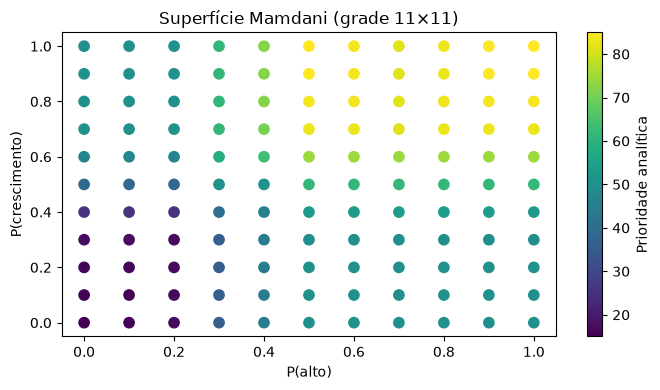

Grade: divergências 34 em 121


In [4]:
grid = []

for a, b in itertools.product(
    np.linspace(0, 1, 11),
    repeat=2
):
    f = mamdani(a, b)

    grid.append((
        a,
        b,
        f,
        int(f >= 50) != int(a >= 0.5)
    ))

g = pd.DataFrame(
    grid,
    columns=[
        "risco",
        "tendencia",
        "fuzzy",
        "divergente"
    ]
)

g.to_csv(
    ROOT / "outputs" / "fuzzy_grade_11x11.csv",
    index=False
)

plt.figure(figsize=(7, 4))

plt.scatter(
    g.risco,
    g.tendencia,
    c=g.fuzzy,
    cmap="viridis",
    s=55
)

plt.colorbar(label="Prioridade analítica")
plt.xlabel("P(alto)")
plt.ylabel("P(crescimento)")
plt.title("Superfície Mamdani (grade 11×11)")
plt.tight_layout()

plt.savefig(
    ROOT / "outputs" / "fuzzy_superficie.png",
    dpi=160
)

plt.show()

print(
    "Grade: divergências",
    g.divergente.sum(),
    "em",
    len(g)
)

## Conferência numérica com scikit-fuzzy

A saída própria usa o centroide calculado com `np.trapezoid`, que é compatível com NumPy 2.x. A conferência externa compara 25 pares de risco/tendência. Havendo `scikit-fuzzy` instalado, a biblioteca é chamada novamente e o resultado local é gravado no JSON. Os números trazidos na revisão independente permanecem em arquivo de proveniência própria.

In [5]:
import itertools
import json

points = [
    (float(x), float(y))
    for x, y in itertools.product(
        np.linspace(0, 1, 5),
        repeat=2
    )
]

try:
    import skfuzzy  # noqa: F401
except ImportError as exc:
    raise ImportError(
        "scikit-fuzzy não encontrado. Execute: python -m pip install -r requirements.txt"
    ) from exc

errors = [
    abs(mamdani(a, b) - mamdani_skfuzzy(a, b))
    for a, b in points
]

diff = max(errors)

assert diff <= 0.3, (
    diff,
    "Mamdani divergiu da referência"
)

status = "executado_e_verificado_localmente"
ncases = len(points)
provenance = "scikit-fuzzy executado na sessão atual do notebook"

print("scikit-fuzzy:", ncases, "casos; diferença máxima =", diff)

metrics = {
    "test_n": len(actual),
    "distinct_probability_pairs": unique,
    "test_divergences": act_div,
    "id3_bn_divergences": id3_bn_div,
    "id3_fuzzy_divergences": id3_fuzzy_div,
    "grid_n": len(g),
    "grid_divergences": int(g.divergente.sum()),
    "skfuzzy_status": status,
    "skfuzzy_cases": ncases,
    "skfuzzy_max_abs_diff": diff,
    "skfuzzy_proveniencia": provenance,
    "prioridade_media_teste": float(actual.prioridade.mean())
}

write_metrics("etapa6.json", metrics)

scikit-fuzzy: 25 casos; diferença máxima = 8.000625101090009e-05


PosixPath('FIA_P3_SegurancaPublica_Equipe5/outputs/etapa6.json')

## Interpretabilidade e uso responsável
A saída fuzzy suaviza a passagem de baixo a alto quando as probabilidades mudam perto de 0,5. O limiar rígido só retorna uma classe. A graduação, entretanto, não garante aumento de acurácia nem autoriza priorização automática de cidadãos, bairros ou ações policiais. É uma ferramenta transparente para revisão estatística dos dados agregados.